# Local features, RANSAC homographies and panoramas

Local features are how a robot recognises the *same physical point* in two images: they drive visual
odometry, SLAM loop closure, structure-from-motion, object localisation and image stitching. This notebook
measures the classic pipeline **detect -> describe -> match -> robustly fit a geometric model** on real images
with a ground-truth homography, then uses it to localise a known object and to stitch a panorama.

**What it does**

1. Detects SIFT and ORB keypoints and measures their speed and repeatability against a ground-truth homography
   (Oxford `graf` viewpoint pair, about 40 degrees of out-of-plane rotation).
2. Matches descriptors with brute force + Lowe's ratio test and sweeps the ratio threshold, scoring every match
   as correct/incorrect with the ground truth.
3. Implements normalised DLT + RANSAC from scratch, then compares OpenCV's estimators
   (RANSAC, LMedS, RHO, USAC variants incl. MAGSAC++) on accuracy, inliers and speed.
4. Localises a known planar object (`box` in `box_in_scene`).
5. Stitches a rotating-camera panorama manually (warp + feather blending) and with `cv2.Stitcher`.

**What you'll learn**

- how SIFT (scale-space DoG + gradient histograms) and ORB (FAST + binary BRIEF) differ and when to use which
- why the ratio test works and how to choose its threshold
- the DLT for homographies, Hartley normalisation and the RANSAC iteration formula
- how the inlier threshold trades accuracy against robustness
- why a homography relates images of a *plane* or of a *purely rotating* camera, and why wide panoramas need spherical warping

**Prerequisites**: notebook `01_image_formation_filtering_edges` (pinhole model, gradients).
Data: `make data-01_classical_cv`. Runs on the CPU in about a minute.

## 0. Setup

Besides the usual seeding/version printout we load the `graf1`/`graf3` pair and the ground-truth homography
`H1to3p` that maps pixels of image 1 to image 3 (estimated by the dataset authors from manually selected
points and refined; the scene is a planar wall painting, so a homography is the exact model).

In [1]:
# --- Setup: imports, seeding, repo-relative paths and the graf pair with its ground truth ---
import time
from io import BytesIO

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage
from IPython.display import display
from scipy.spatial import cKDTree

from cvlab import device as cvdevice
from cvlab import geometry, io, viz
from cvlab.bench import Timer, benchmark

device = cvdevice.setup(seed=0)
viz.set_style()
cv2.setRNGSeed(0)
PROJECT = "01_classical_cv"
ROOT = io.repo_root()
FEAT = io.data_dir("01_classical_cv", "features")
STITCH = io.data_dir("01_classical_cv", "stitching")
RESULTS_DIR = io.project_dir(PROJECT) / "results"
RESULTS_DIR.mkdir(exist_ok=True)
results = {}
T_START = time.perf_counter()  # wall-clock start; the notebook runtime is reported in the summary cell


def show_jpeg(fig, quality=80):
    # Photo-like figures are embedded as JPEG to keep the committed notebook small.
    buf = BytesIO()
    fig.savefig(buf, format="jpeg", pil_kwargs={"quality": quality})
    plt.close(fig)
    display(IPImage(buf.getvalue()))


g1 = cv2.imread(str(FEAT / "graf1.png"), cv2.IMREAD_GRAYSCALE)  # (640, 800) uint8
g3 = cv2.imread(str(FEAT / "graf3.png"), cv2.IMREAD_GRAYSCALE)
fs = cv2.FileStorage(str(FEAT / "H1to3p.xml"), cv2.FILE_STORAGE_READ)
H_gt = fs.getNode("H13").mat()  # 3x3, maps graf1 pixels -> graf3 pixels
fs.release()
print("data:", FEAT.relative_to(ROOT), "| graf1", g1.shape, "| graf3", g3.shape)
print("H_gt =\n", H_gt.round(4))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
data: data/01_classical_cv/features | graf1 (640, 800) | graf3 (640, 800)
H_gt =
 [[ 7.629000e-01 -2.992000e-01  2.256712e+02]
 [ 3.344000e-01  1.014400e+00 -7.700000e+01]
 [ 3.000000e-04 -0.000000e+00  1.000000e+00]]


A homography acts on homogeneous pixels, $\tilde{\mathbf{x}}' \sim H\tilde{\mathbf{x}}$, so mapping points needs a division by the
third coordinate. In the overlay below, aligned regions look grey; magenta/green fringes mark things that are **not on the
wall plane** (the white bar and the car in front of the wall show parallax), where no homography can align the two views. `cv2.perspectiveTransform` does that, with one **OpenCV 5 gotcha**: point arrays returned by many
functions are now `(N, 2)`, but `perspectiveTransform` still requires `(N, 1, 2)` and raises an assertion otherwise.

(N, 2) input rejected: (-215:Assertion failed) scn + 1 == m.cols in function 'perspectiveTransform'
(N, 1, 2) input works:
 [[225.67 -77.  ]
 [383.63 336.3 ]]


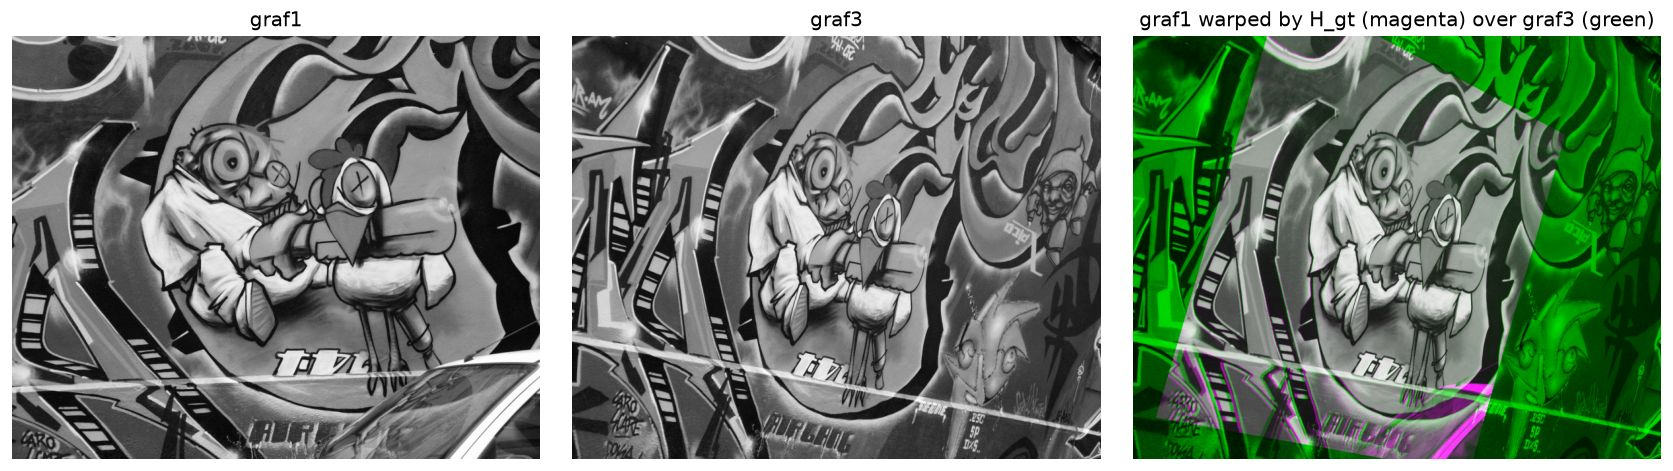

In [2]:
# --- Map points with a homography; show the OpenCV 5 shape requirement ---
def warp_pts(pts, H):
    # (N, 2) -> (N, 1, 2) float64 for OpenCV, back to (N, 2)
    return cv2.perspectiveTransform(np.asarray(pts, np.float64).reshape(-1, 1, 2), H).reshape(-1, 2)

demo = np.array([[0.0, 0.0], [400.0, 320.0]])
try:
    cv2.perspectiveTransform(demo, H_gt)
except cv2.error as e:
    print("(N, 2) input rejected:", str(e).strip().split("error: ")[-1])
print("(N, 1, 2) input works:\n", warp_pts(demo, H_gt).round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
warped = cv2.warpPerspective(g1, H_gt, (g3.shape[1], g3.shape[0]))
for ax, im, title in [(axes[0], g1, "graf1"), (axes[1], g3, "graf3"),
                      (axes[2], np.dstack([warped, g3, warped]), "graf1 warped by H_gt (magenta) over graf3 (green)")]:
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
show_jpeg(fig)

## 1. Keypoint detectors: SIFT vs ORB

**SIFT** (Lowe 2004) finds extrema of the Difference-of-Gaussians scale space
$D(\mathbf{x}, \sigma) = (G_{k\sigma} - G_{\sigma}) * I$, which approximates the scale-normalised Laplacian, assigns each
keypoint a dominant gradient orientation, and describes a $16\times16$ patch (rotated and scaled to the keypoint) by
$4\times4$ cells of 8-bin gradient-orientation histograms: a 128-D float vector compared with the $L_2$ distance.

**ORB** (Rublee et al. 2011) detects FAST corners on an image pyramid, ranks them with the Harris score, assigns an
orientation from the intensity centroid, and describes them with *rotated BRIEF*: 256 binary intensity comparisons
(32 bytes) compared with the Hamming distance (XOR + popcount, very fast).

Both are invariant to in-plane rotation and scale, neither is invariant to strong out-of-plane (affine/perspective)
distortion, which is exactly what the `graf` pair tests. We cap both at 4000 features.

In [3]:
# --- Detect + describe with SIFT and ORB; record counts, descriptor size and runtime ---
detectors = {"SIFT": cv2.SIFT_create(nfeatures=4000), "ORB": cv2.ORB_create(nfeatures=4000)}
norms = {"SIFT": cv2.NORM_L2, "ORB": cv2.NORM_HAMMING}
feats, det_rows = {}, []
for name, det in detectors.items():
    k1, d1 = det.detectAndCompute(g1, None)
    k3, d3 = det.detectAndCompute(g3, None)
    feats[name] = (k1, d1, k3, d3)
    t = benchmark(det.detectAndCompute, g1, None, warmup=2, iters=10, cuda=False)
    det_rows.append({"detector": name, "keypoints_graf1": len(k1), "keypoints_graf3": len(k3),
                     "descriptor": f"{d1.shape[1]} x {d1.dtype}", "bytes_per_descriptor": d1[0].nbytes,
                     "detect+describe_ms (640x800)": t["mean_ms"]})
df_det = pd.DataFrame(det_rows)
df_det.round(2)

,detector,keypoints_graf1,keypoints_graf3,descriptor,bytes_per_descriptor,detect+describe_ms (640x800)
0,SIFT,2665,3498,128 x float32,512,21.35
1,ORB,4000,4000,32 x uint8,32,7.13


Visualising a subset of keypoints with their scale (circle radius) and orientation (line) shows the different
behaviour: SIFT spreads over many scales including large blobs, ORB concentrates on corner-like structure.

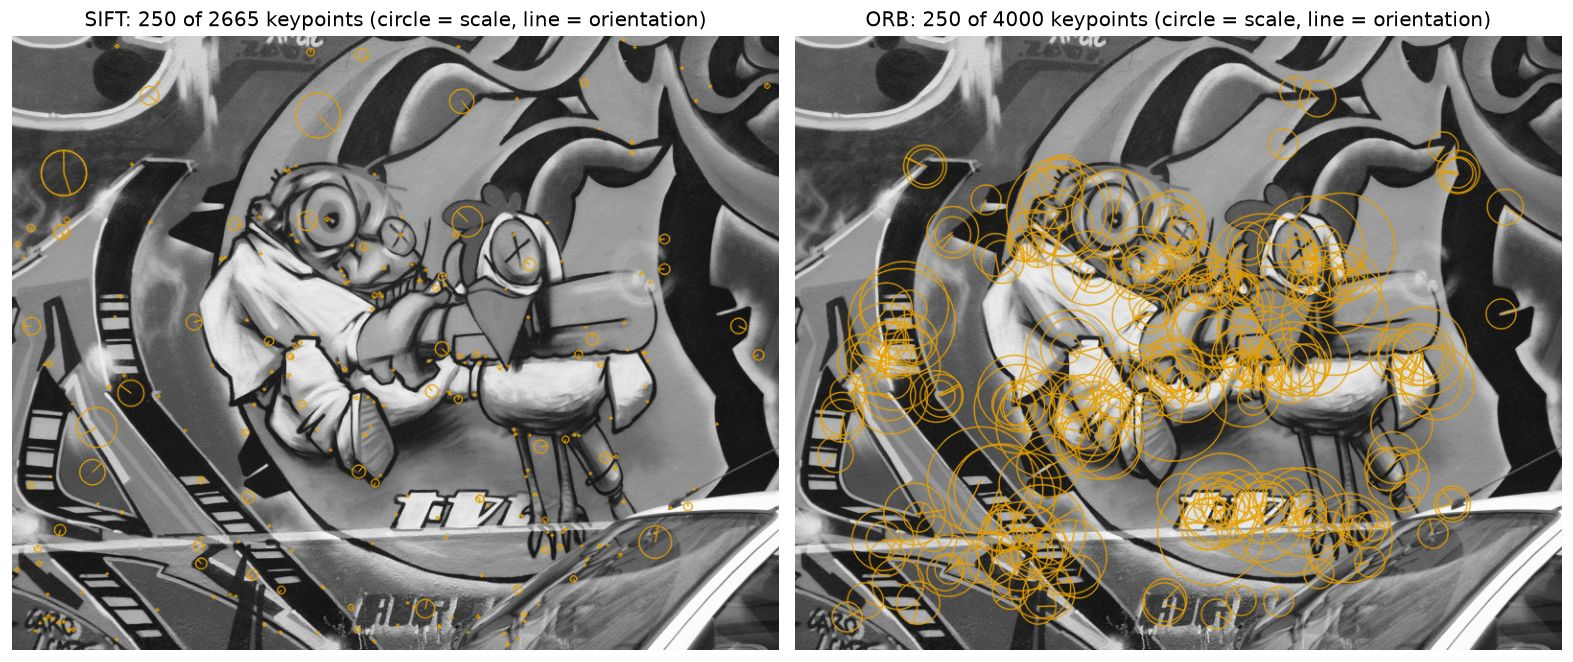

In [4]:
# --- Draw 250 random keypoints per detector with scale and orientation ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
pick = np.random.default_rng(0)
for ax, name in zip(axes, feats):
    k1 = feats[name][0]
    sub = [k1[i] for i in pick.choice(len(k1), 250, replace=False)]
    vis = cv2.drawKeypoints(cv2.cvtColor(g1, cv2.COLOR_GRAY2RGB), sub, None, color=viz.color(1),
                            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    ax.imshow(vis)
    ax.axis("off")
    ax.set_title(f"{name}: 250 of {len(k1)} keypoints (circle = scale, line = orientation)")
show_jpeg(fig)

### 1.1 Repeatability with the ground-truth homography

A good detector fires on the *same physical points* in both images. We map every keypoint of image 1 into image 3
with $H_{gt}$ and count how many land within $\varepsilon = 3$ px of a keypoint detected in image 3
(nearest neighbour via a k-d tree). This is a simplified, location-only version of the classic repeatability
criterion of Mikolajczyk et al., which also compares region overlap. Dense detections can coincide by chance, so we also
report the same score for uniformly random points (chance level).

In [5]:
# --- Location repeatability at 3 px for SIFT and ORB ---
def repeatability(k1, k3, H, shape3, eps=3.0, random_pts=False):
    p1 = warp_pts([k.pt for k in k1], H)
    if random_pts:  # chance level: the same number of uniformly random points in graf1
        p1 = warp_pts(np.random.default_rng(0).uniform([0, 0], [g1.shape[1], g1.shape[0]], (len(k1), 2)), H)
    p3 = np.float64([k.pt for k in k3])
    h, w = shape3
    inside = (p1[:, 0] >= 0) & (p1[:, 0] < w) & (p1[:, 1] >= 0) & (p1[:, 1] < h)
    dist, _ = cKDTree(p3).query(p1[inside])
    return float((dist < eps).mean()), int(inside.sum())

for row in det_rows:
    k1, _, k3, _ = feats[row["detector"]]
    row["repeatability@3px"], row["visible_in_graf3"] = repeatability(k1, k3, H_gt, g3.shape)
    row["chance_level@3px"], _ = repeatability(k1, k3, H_gt, g3.shape, random_pts=True)
df_det = pd.DataFrame(det_rows)
results["detectors"] = det_rows
df_det.round(3)

,detector,keypoints_graf1,keypoints_graf3,descriptor,bytes_per_descriptor,detect+describe_ms (640x800),repeatability@3px,visible_in_graf3,chance_level@3px
0,SIFT,2665,3498,128 x float32,512,21.350,0.486,2650,0.148
1,ORB,4000,4000,32 x uint8,32,7.135,0.780,4000,0.126


## 2. Descriptor matching and Lowe's ratio test

For every descriptor in image 1 we find its two nearest neighbours in image 3 (`BFMatcher.knnMatch(k=2)`,
exhaustive search). A distinctive feature has one clearly best match, an ambiguous one (repeated texture, or no true
correspondence at all) has two similar candidates. **Lowe's ratio test** keeps a match only if

$$ \frac{d_1}{d_2} < r, \qquad d_1 \le d_2 \text{ the two smallest descriptor distances.} $$

Lowe reported $r = 0.8$ removing 90% of false matches while discarding < 5% of correct ones on his data. With $H_{gt}$ we
can label each match: correct if $\lVert \pi(H_{gt}\tilde{\mathbf{x}}_1) - \mathbf{x}_3 \rVert < 3$ px. We also try
**cross-checking** (keep $i \leftrightarrow j$ only if each is the other's nearest neighbour). In OpenCV 5 `knnMatch` and
`match` return tuples of `DMatch` objects.

In [6]:
# --- kNN matching, ground-truth labels and a sweep over the ratio threshold ---
match_data, ratio_rows, cc_rows = {}, [], []
for name, (k1, d1, k3, d3) in feats.items():
    knn = [m for m in cv2.BFMatcher(norms[name]).knnMatch(d1, d3, k=2) if len(m) == 2]
    ratio = np.array([m.distance / max(n.distance, 1e-9) for m, n in knn])
    p1 = np.float64([k1[m.queryIdx].pt for m, _ in knn])
    p3 = np.float64([k3[m.trainIdx].pt for m, _ in knn])
    size1 = np.array([k1[m.queryIdx].size for m, _ in knn])  # keypoint diameter [px]
    err = np.linalg.norm(warp_pts(p1, H_gt) - p3, axis=1)   # ground-truth transfer error [px]
    match_data[name] = dict(ratio=ratio, p1=p1, p3=p3, err=err, size=size1, knn=knn)
    for r in np.round(np.arange(0.5, 1.001, 0.05), 2):
        sel = ratio < r if r < 1 else np.ones(len(ratio), bool)
        ratio_rows.append({"detector": name, "ratio": r, "matches": int(sel.sum()),
                           "correct": int((err[sel] < 3).sum()), "precision": float((err[sel] < 3).mean())})
    cc = cv2.BFMatcher(norms[name], crossCheck=True).match(d1, d3)
    e_cc = np.linalg.norm(warp_pts([k1[m.queryIdx].pt for m in cc], H_gt)
                          - np.float64([k3[m.trainIdx].pt for m in cc]), axis=1)
    cc_rows.append({"detector": name, "cross-check matches": len(cc), "correct": int((e_cc < 3).sum()),
                    "precision": float((e_cc < 3).mean())})
df_ratio = pd.DataFrame(ratio_rows)
results["ratio_sweep"] = ratio_rows
results["cross_check"] = cc_rows
display(pd.DataFrame(cc_rows).round(3))
df_ratio.pivot(index="ratio", columns="detector", values=["matches", "correct", "precision"]).round(3)

,detector,cross-check matches,correct,precision
0,SIFT,1217,548,0.450
1,ORB,1363,605,0.444


matches         correct        precision       
detector     ORB    SIFT     ORB   SIFT       ORB   SIFT
ratio                                                   
0.50        14.0    69.0    12.0   51.0     0.857  0.739
0.55        25.0   124.0    22.0   90.0     0.880  0.726
0.60        47.0   206.0    38.0  142.0     0.809  0.689
0.65        80.0   300.0    62.0  203.0     0.775  0.677
0.70       152.0   378.0   105.0  253.0     0.691  0.669
0.75       267.0   522.0   192.0  331.0     0.719  0.634
0.80       434.0   686.0   299.0  394.0     0.689  0.574
0.85       728.0   878.0   431.0  464.0     0.592  0.528
0.90      1230.0  1158.0   604.0  519.0     0.491  0.448
0.95      2137.0  1668.0   806.0  572.0     0.377  0.343
1.00      4000.0  2665.0  1065.0  613.0     0.266  0.230

Precision on this pair is lower than on easy image pairs. Where do the wrong matches go? The histogram of the ground-truth
error of ratio-test matches ($r = 0.8$) separates *gross* outliers (hundreds of pixels) from *near misses* a few pixels
away. Splitting SIFT's matches by keypoint size shows which ones are affected most.

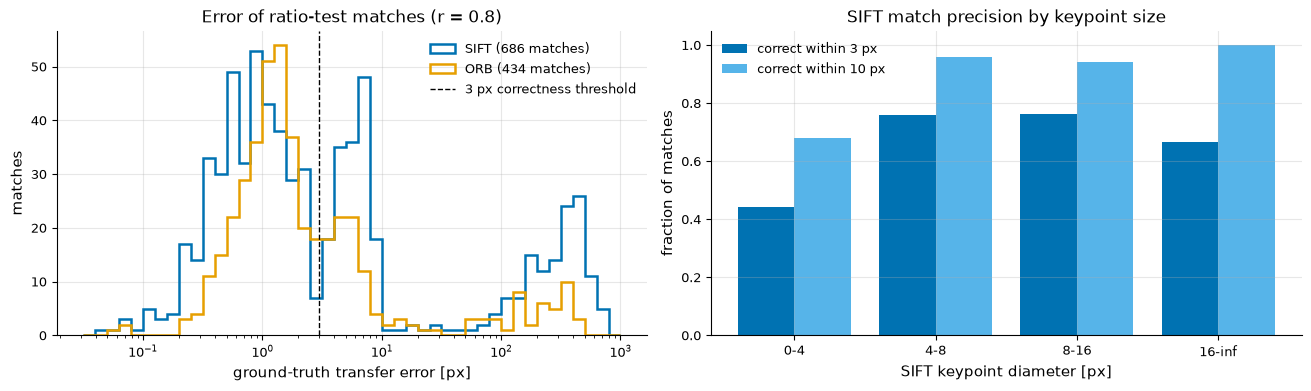

,sift_keypoint_size_px,matches,median_error_px,precision@3px,precision@10px
0,0-4,389,4.958,0.442,0.679
1,4-8,170,1.125,0.759,0.959
2,8-16,88,1.692,0.761,0.943
3,16-inf,39,2.186,0.667,1.000


In [7]:
# --- Where do the wrong matches go? GT error histogram and SIFT error by keypoint size ---
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
bins = np.logspace(-1.5, 3, 46)
for i, name in enumerate(match_data):
    md_ = match_data[name]
    sel = md_["ratio"] < 0.8
    axes[0].hist(np.clip(md_["err"][sel], bins[0], bins[-1]), bins=bins, histtype="step", lw=1.8,
                 color=viz.color(i, True), label=f"{name} ({sel.sum()} matches)")
axes[0].axvline(3, color="k", ls="--", lw=1, label="3 px correctness threshold")
axes[0].set_xscale("log")
axes[0].set_xlabel("ground-truth transfer error [px]")
axes[0].set_ylabel("matches")
axes[0].set_title("Error of ratio-test matches (r = 0.8)")
axes[0].legend()

s = match_data["SIFT"]
sel = s["ratio"] < 0.8
size_bins = [(0, 4), (4, 8), (8, 16), (16, 1000)]
size_rows = []
for lo, hi in size_bins:
    m = sel & (s["size"] >= lo) & (s["size"] < hi)
    size_rows.append({"sift_keypoint_size_px": f"{lo}-{hi if hi < 1000 else 'inf'}", "matches": int(m.sum()),
                      "median_error_px": float(np.median(s["err"][m])), "precision@3px": float((s["err"][m] < 3).mean()),
                      "precision@10px": float((s["err"][m] < 10).mean())})
df_size = pd.DataFrame(size_rows)
xpos = np.arange(len(df_size))
axes[1].bar(xpos - 0.2, df_size["precision@3px"], 0.4, color=viz.color(0, True), label="correct within 3 px")
axes[1].bar(xpos + 0.2, df_size["precision@10px"], 0.4, color=viz.color(4, True), label="correct within 10 px")
axes[1].set_xticks(xpos, df_size["sift_keypoint_size_px"])
axes[1].set_xlabel("SIFT keypoint diameter [px]")
axes[1].set_ylabel("fraction of matches")
axes[1].set_title("SIFT match precision by keypoint size")
axes[1].legend()
plt.show()
results["sift_error_by_size"] = size_rows
df_size.round(3)

## 3. Robust homography estimation

**Model.** A homography has 8 degrees of freedom; each correspondence $\mathbf{x}_i \leftrightarrow \mathbf{x}'_i$ gives
two linear equations in the 9 entries $\mathbf{h}$ of $H$ (from $\tilde{\mathbf{x}}'_i \times H\tilde{\mathbf{x}}_i = 0$):

$$
\begin{bmatrix}
x & y & 1 & 0 & 0 & 0 & -u x & -u y & -u \\
0 & 0 & 0 & x & y & 1 & -v x & -v y & -v
\end{bmatrix}\mathbf{h} = \mathbf{0},
$$

so 4 points determine $H$. With $n \ge 4$ points, the **DLT** solution is the right singular vector of the stacked
$2n\times 9$ matrix $A$ with the smallest singular value. **Hartley normalisation** (translate each point set to zero
mean and scale it to mean distance $\sqrt2$) makes $A$ well conditioned; then $H = T'^{-1}\hat H T$.

**RANSAC** (Fischler & Bolles 1981): repeatedly fit $H$ to a random minimal sample of $s = 4$ matches, count the matches
with transfer error below $\tau$, keep the best model and finally refit it on all its inliers. To draw at least one
all-inlier sample with probability $p$ when a fraction $w$ of the matches are inliers you need

$$ N = \frac{\log(1 - p)}{\log(1 - w^{s})} $$

iterations, which explodes as $w$ drops or the sample size $s$ grows.

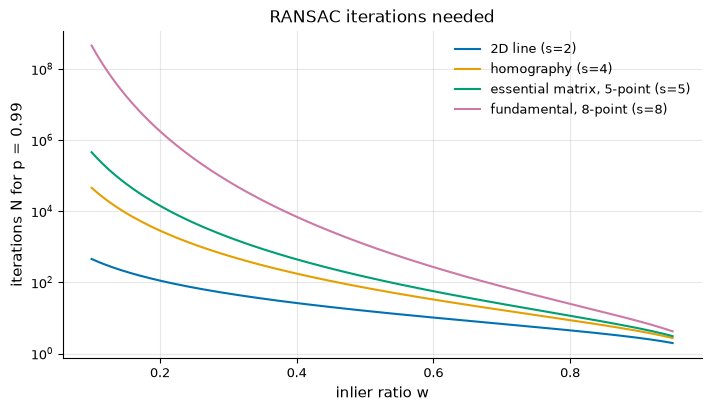

In [8]:
# --- RANSAC iteration count vs inlier ratio for different minimal sample sizes (p = 0.99) ---
w = np.linspace(0.1, 0.95, 200)
fig, ax = plt.subplots(figsize=(7, 4))
for i, (s_, label) in enumerate([(2, "2D line (s=2)"), (4, "homography (s=4)"),
                                 (5, "essential matrix, 5-point (s=5)"), (8, "fundamental, 8-point (s=8)")]):
    ax.plot(w, np.log(1 - 0.99) / np.log(1 - w**s_), color=viz.color(i, True), label=label)
ax.set_yscale("log")
ax.set_xlabel("inlier ratio w")
ax.set_ylabel("iterations N for p = 0.99")
ax.set_title("RANSAC iterations needed")
ax.legend()
plt.show()

Now the estimator itself, in about 40 lines of NumPy. The inlier test uses the one-way **transfer error**
$e_i = \lVert \pi(H\tilde{\mathbf{x}}_i) - \mathbf{x}'_i \rVert$ (pixels in image 3), and the number of iterations is updated
adaptively from the best inlier ratio seen so far.

In [9]:
# --- Normalised DLT and RANSAC from scratch (NumPy) ---
def normalize_points(x):
    c = x.mean(axis=0)
    s = np.sqrt(2) / np.mean(np.linalg.norm(x - c, axis=1))
    T = np.array([[s, 0, -s * c[0]], [0, s, -s * c[1]], [0, 0, 1.0]])
    return (x - c) * s, T

def dlt_homography(x1, x2):
    n1, T1 = normalize_points(x1)
    n2, T2 = normalize_points(x2)
    x, y = n1.T
    u, v = n2.T
    z, o = np.zeros_like(x), np.ones_like(x)
    A = np.empty((2 * len(x), 9))
    A[0::2] = np.stack([x, y, o, z, z, z, -u * x, -u * y, -u], axis=1)
    A[1::2] = np.stack([z, z, z, x, y, o, -v * x, -v * y, -v], axis=1)
    H = np.linalg.inv(T2) @ np.linalg.svd(A)[2][-1].reshape(3, 3) @ T1  # smallest singular vector
    return H / H[2, 2]

def transfer_error(H, x1, x2):
    p = np.c_[x1, np.ones(len(x1))] @ H.T
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.linalg.norm(p[:, :2] / p[:, 2:3] - x2, axis=1)

def ransac_homography(x1, x2, thresh=3.0, p=0.99, max_iters=5000, seed=0):
    rng = np.random.default_rng(seed)
    best = np.zeros(len(x1), bool)
    n_needed, it = max_iters, 0
    while it < n_needed:
        idx = rng.choice(len(x1), 4, replace=False)
        it += 1
        with np.errstate(all="ignore"):
            try:
                inl = transfer_error(dlt_homography(x1[idx], x2[idx]), x1, x2) < thresh
            except np.linalg.LinAlgError:  # degenerate (e.g. collinear) sample
                continue
        if inl.sum() > best.sum():
            best = inl
            w_hat = inl.mean()
            n_needed = min(max_iters, int(np.ceil(np.log(1 - p) / np.log(max(1 - w_hat**4, 1e-12)))))
    H = dlt_homography(x1[best], x2[best])  # refit on all inliers
    return H, transfer_error(H, x1, x2) < thresh, it

h1, w1 = g1.shape
corners1 = np.float64([[0, 0], [w1 - 1, 0], [w1 - 1, h1 - 1], [0, h1 - 1]])

def corner_error(H):
    # mean distance between the image corners mapped by H and by H_gt [px in graf3]
    return float(np.linalg.norm(warp_pts(corners1, H) - warp_pts(corners1, H_gt), axis=1).mean())

s = match_data["SIFT"]
sel = s["ratio"] < 0.8
x1s, x3s, err_s = s["p1"][sel], s["p3"][sel], s["err"][sel]
H_np, inl_np, iters = ransac_homography(x1s, x3s, thresh=3.0)
H_cv, mask_cv = cv2.findHomography(x1s, x3s, cv2.RANSAC, 3.0)
print(f"{len(x1s)} SIFT matches (ratio < 0.8), {int((err_s < 3).sum())} correct by ground truth")
print(f"NumPy RANSAC : {iters:4d} iterations, {inl_np.sum()} inliers, corner error {corner_error(H_np):.2f} px")
print(f"cv2 RANSAC   :        {int(mask_cv.sum())} inliers, corner error {corner_error(H_cv):.2f} px, "
      f"mask shape {mask_cv.shape} {mask_cv.dtype}")
ce_gt = corner_error(dlt_homography(x1s[err_s < 3], x3s[err_s < 3]))
print(f"DLT on GT-correct matches only: corner error {ce_gt:.2f} px")
results["ransac_from_scratch"] = {"matches": len(x1s), "gt_correct": int((err_s < 3).sum()),
                                  "numpy_iterations": iters, "numpy_inliers": int(inl_np.sum()),
                                  "numpy_corner_error_px": corner_error(H_np), "cv2_inliers": int(mask_cv.sum()),
                                  "cv2_corner_error_px": corner_error(H_cv), "dlt_gt_only_corner_error_px": ce_gt}

686 SIFT matches (ratio < 0.8), 394 correct by ground truth
NumPy RANSAC :   40 iterations, 396 inliers, corner error 1.35 px
cv2 RANSAC   :        453 inliers, corner error 5.06 px, mask shape (686, 1) uint8
DLT on GT-correct matches only: corner error 0.69 px


### 3.1 The inlier threshold $\tau$

$\tau$ encodes how much localisation noise we expect. Too small and true matches with a few pixels of error are rejected
(few inliers, unstable fit); too large and near-miss outliers are accepted and bias the fit. **MAGSAC++**
(Barath et al. 2020; `cv2.USAC_MAGSAC`) avoids a hard choice by marginalising over noise scales up to $\tau$ and weighting
points accordingly, so it should be less sensitive. We sweep $\tau$ on the SIFT matches and report the inlier fraction,
the fraction of inliers that are truly correct (< 3 px by ground truth) and the corner error.

In [10]:
# --- Sweep the inlier threshold for cv2 RANSAC and MAGSAC++ on the SIFT matches ---
tau_rows = []
for mname, flag in [("RANSAC", cv2.RANSAC), ("MAGSAC++", cv2.USAC_MAGSAC)]:
    for tau in [0.5, 1.0, 2.0, 3.0, 5.0, 8.0, 12.0, 20.0]:
        H, mask = cv2.findHomography(x1s, x3s, flag, tau)
        inl = mask.ravel().astype(bool)
        tau_rows.append({"method": mname, "tau_px": tau, "inlier_fraction": float(inl.mean()),
                         "inliers_truly_correct": float((err_s[inl] < 3).mean()),
                         "corner_error_px": corner_error(H)})
df_tau = pd.DataFrame(tau_rows)
results["threshold_sweep_sift"] = tau_rows
df_tau.pivot(index="tau_px", columns="method", values=["inlier_fraction", "inliers_truly_correct", "corner_error_px"]).round(3)

inlier_fraction        inliers_truly_correct        corner_error_px  \
method        MAGSAC++ RANSAC              MAGSAC++ RANSAC        MAGSAC++   
tau_px                                                                       
0.5              0.085  0.178                 0.966  1.000           3.415   
1.0              0.242  0.356                 0.970  1.000           3.395   
2.0              0.526  0.515                 0.812  1.000           3.354   
3.0              0.694  0.660                 0.750  0.742           3.341   
5.0              0.780  0.764                 0.735  0.731           3.367   
8.0              0.796  0.796                 0.722  0.722           3.367   
12.0             0.800  0.800                 0.718  0.718           3.367   
20.0             0.806  0.806                 0.712  0.712           3.341   

               
method RANSAC  
tau_px         
0.5     2.294  
1.0     1.954  
2.0     1.453  
3.0     5.059  
5.0     4.696  
8.0     4.275  
12.0    3.539  
20.0    3.579

### 3.2 Estimator comparison

OpenCV offers several robust estimators through `findHomography`:

- `RANSAC`: the classic algorithm with a final least-squares refinement;
- `LMEDS`: least median of squares, needs no threshold but breaks down above 50% outliers;
- `RHO`: PROSAC-based (samples high-quality matches first), very fast;
- `USAC_DEFAULT`, `USAC_ACCURATE` (with graph-cut local optimisation), `USAC_MAGSAC` (MAGSAC++): the newer USAC framework.

In OpenCV 5 these estimators are **deterministic** for a given input (the check below changes `cv2.setRNGSeed` and gets
identical inlier counts). To still measure robustness we run every estimator on 20 random subsets containing 80% of the matches
and report the median and the worst corner error, plus the runtime on the full match set. Our NumPy RANSAC runs with a
different seed per subset. The inlier column counts matches with transfer error < 3 px under each estimator's final $H$.

In [11]:
# --- Compare estimators on SIFT and ORB matches: accuracy over 20 random 80% subsets + runtime ---
estimators = {"RANSAC": cv2.RANSAC, "LMEDS": cv2.LMEDS, "RHO": cv2.RHO, "USAC_DEFAULT": cv2.USAC_DEFAULT,
              "USAC_ACCURATE": cv2.USAC_ACCURATE, "MAGSAC++": cv2.USAC_MAGSAC, "NumPy RANSAC (ours)": None}
for seed in range(3):  # determinism check
    cv2.setRNGSeed(seed)
    print(f"cv2.setRNGSeed({seed}): RANSAC inliers {int(cv2.findHomography(x1s, x3s, cv2.RANSAC, 3.0)[1].sum())}, "
          f"MAGSAC++ inliers {int(cv2.findHomography(x1s, x3s, cv2.USAC_MAGSAC, 3.0)[1].sum())}")
est_rows = []
for det_name in ["SIFT", "ORB"]:
    d = match_data[det_name]
    sel = d["ratio"] < 0.8
    xa, xb = d["p1"][sel], d["p3"][sel]
    subsets = [np.random.default_rng(100 + i).choice(len(xa), int(0.8 * len(xa)), replace=False) for i in range(20)]
    for ename, flag in estimators.items():
        if flag is None:
            fit = lambda a, b, seed=0: ransac_homography(a, b, 3.0, seed=seed)[0]  # noqa: E731
        else:
            fit = lambda a, b, seed=0, flag=flag: cv2.findHomography(a, b, flag, 3.0)[0]  # noqa: E731
        errs = [corner_error(fit(xa[ix], xb[ix], seed=i)) for i, ix in enumerate(subsets)]
        t = benchmark(fit, xa, xb, warmup=2, iters=5 if flag is None else 30, cuda=False)
        H_full = fit(xa, xb)
        est_rows.append({"matches": det_name, "estimator": ename, "n_matches": len(xa),
                         "inliers (tau=3)": int((transfer_error(H_full, xa, xb) < 3).sum()),
                         "corner_err_median_px": float(np.median(errs)), "corner_err_worst_px": float(np.max(errs)),
                         "time_ms": t["mean_ms"]})
df_est = pd.DataFrame(est_rows)
results["estimators"] = est_rows
df_est.round(2)

cv2.setRNGSeed(0): RANSAC inliers 453, MAGSAC++ inliers 476
cv2.setRNGSeed(1): RANSAC inliers 453, MAGSAC++ inliers 476
cv2.setRNGSeed(2): RANSAC inliers 453, MAGSAC++ inliers 476


,matches,estimator,n_matches,inliers (tau=3),corner_err_median_px,corner_err_worst_px,time_ms
0,SIFT,RANSAC,686,453,4.38,5.95,0.70
1,SIFT,LMEDS,686,418,3.43,3.83,0.97
2,SIFT,RHO,686,417,3.98,6.39,0.17
3,SIFT,USAC_DEFAULT,686,472,3.91,4.50,1.77
4,SIFT,USAC_ACCURATE,686,473,4.06,4.50,0.91
5,SIFT,MAGSAC++,686,476,3.43,4.57,0.50
6,SIFT,NumPy RANSAC (ours),686,396,4.15,6.31,9.19
7,ORB,RANSAC,434,299,1.96,8.63,0.58
8,ORB,LMEDS,434,315,2.52,2.84,1.33
9,ORB,RHO,434,285,1.67,4.10,0.12


## 4. Application: localising a known planar object

A robot that knows what an object looks like (a box face, a label, a planar marker) can find it in a cluttered scene
with the same pipeline: match template features to the scene, fit a homography with MAGSAC++ and project the template's
corners. With calibrated intrinsics $K$, the homography of a plane also encodes the object's pose
($H \propto K[\mathbf{r}_1\ \mathbf{r}_2\ \mathbf{t}]$, see `cv2.decomposeHomographyMat`); project 07 does this properly with PnP.

{'template_keypoints': 604, 'scene_keypoints': 969, 'ratio_matches': 80, 'magsac_inliers': 75}


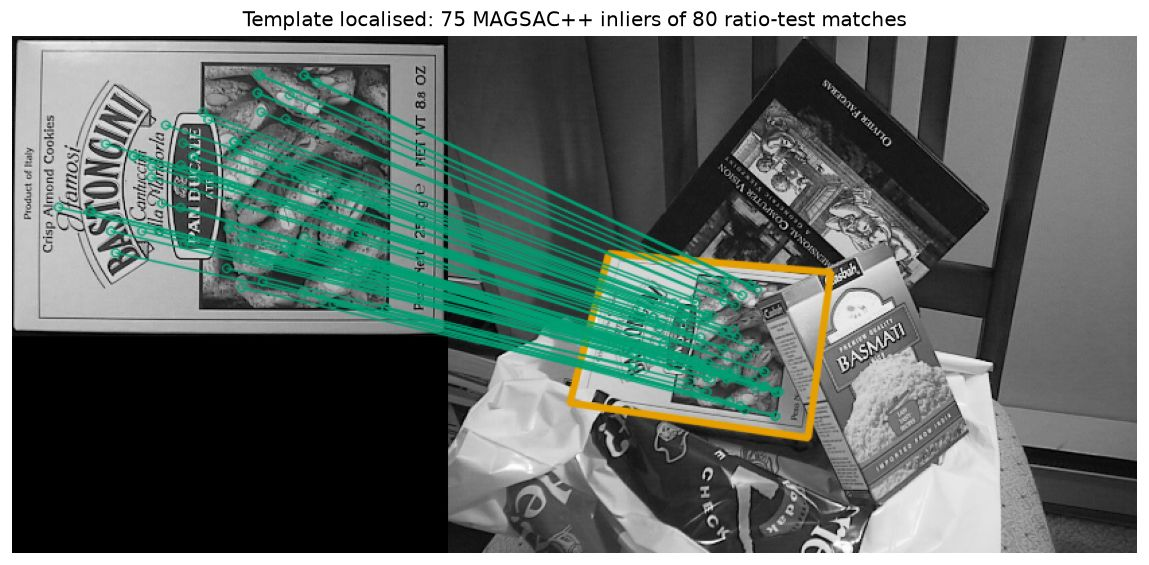

In [12]:
# --- Find box.png inside box_in_scene.png with SIFT + ratio test + MAGSAC++ ---
box = cv2.imread(str(FEAT / "box.png"), cv2.IMREAD_GRAYSCALE)            # (223, 324) template
scene = cv2.imread(str(FEAT / "box_in_scene.png"), cv2.IMREAD_GRAYSCALE)  # (384, 512) cluttered scene
sift = cv2.SIFT_create()
kb, db = sift.detectAndCompute(box, None)
ks, ds = sift.detectAndCompute(scene, None)
good = [m for m, n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(db, ds, k=2) if m.distance < 0.75 * n.distance]
pb = np.float64([kb[m.queryIdx].pt for m in good])
ps = np.float64([ks[m.trainIdx].pt for m in good])
H_box, mask = cv2.findHomography(pb, ps, cv2.USAC_MAGSAC, 3.0)
inliers = [m for m, keep in zip(good, mask.ravel()) if keep]
hb, wb = box.shape
outline = warp_pts([[0, 0], [wb - 1, 0], [wb - 1, hb - 1], [0, hb - 1]], H_box)  # template corners in the scene
scene_vis = cv2.cvtColor(scene, cv2.COLOR_GRAY2RGB)
cv2.polylines(scene_vis, [outline.round().astype(np.int32).reshape(-1, 1, 2)], True, viz.color(1), 3, cv2.LINE_AA)
match_vis = cv2.drawMatches(cv2.cvtColor(box, cv2.COLOR_GRAY2RGB), kb, scene_vis, ks, inliers, None,
                            matchColor=viz.color(2), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
results["object_localization"] = {"template_keypoints": len(kb), "scene_keypoints": len(ks),
                                  "ratio_matches": len(good), "magsac_inliers": len(inliers)}
print(results["object_localization"])
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.imshow(match_vis)
ax.axis("off")
ax.set_title(f"Template localised: {len(inliers)} MAGSAC++ inliers of {len(good)} ratio-test matches")
viz.savefig(fig, PROJECT, "object_localization")
show_jpeg(fig)

The same image, downscaled, is the project thumbnail.

In [13]:
# --- Save a ~420 px wide thumbnail for the root README project table ---
thumb = io.resize_max(match_vis, 420)
fig = plt.figure(figsize=(thumb.shape[1] / 100, thumb.shape[0] / 100), dpi=100)
fig.add_axes([0, 0, 1, 1]).imshow(thumb)
fig.axes[0].axis("off")
path = viz.savefig(fig, PROJECT, "thumb", dpi=100)
plt.close(fig)
print("saved", path.relative_to(ROOT), thumb.shape)

saved assets/01_classical_cv/thumb.png (193, 420, 3)


## 5. Panorama stitching

When does a homography relate two photos? Two cases:

1. the scene is a **plane** (as for `graf` and the box face), or
2. the camera **only rotates** about its optical centre: then $\tilde{\mathbf{x}}' \sim K R K^{-1}\tilde{\mathbf{x}}$ for *any* scene depth,
   because rays through the same centre are just re-projected onto a rotated image plane.

The `boat` sequence (six photos of a harbour from a rotating handheld camera) is case 2. We first stitch three frames by
hand: estimate pairwise homographies to the middle frame, compute the bounding box of all warped images, add a translation
so everything has positive coordinates, warp and blend. **Overwrite** blending shows hard seams; **feathering** weights each
image by its distance to the image border, $I = \sum_k w_k I_k / \sum_k w_k$, which hides small exposure differences.

canvas 2162 x 857 px | mean |boat2 - boat3| in their overlap after warping: 6.5 grey levels


,pair,ratio_matches,magsac_inliers
0,boat1->boat2,514,479
1,boat2->boat3,432,349
2,boat3->boat4,246,212
3,boat4->boat5,453,417
4,boat5->boat6,691,559


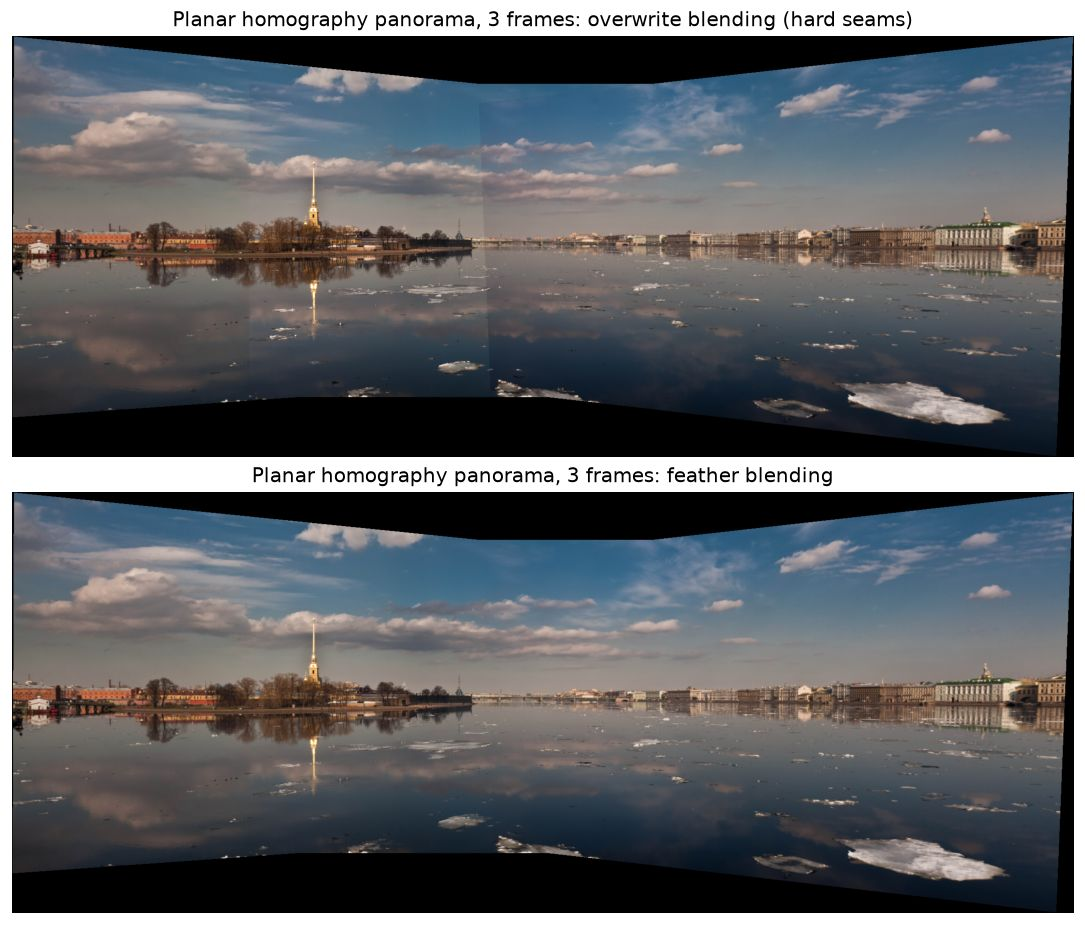

In [14]:
# --- Manual 3-image panorama (boat2-4 onto boat3's image plane) with overwrite vs feather blending ---
boats = [io.read_image(STITCH / f"boat{i}.jpg", max_side=960) for i in range(1, 7)]  # RGB (640, 960, 3)
sift4k = cv2.SIFT_create(nfeatures=4000)
bfeats = [sift4k.detectAndCompute(cv2.cvtColor(b, cv2.COLOR_RGB2GRAY), None) for b in boats]

def pair_homography(i, j):
    # homography mapping boat i -> boat j, plus match statistics
    (ka, da), (kb_, db_) = bfeats[i], bfeats[j]
    good = [m for m, n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(da, db_, k=2) if m.distance < 0.75 * n.distance]
    pa = np.float64([ka[m.queryIdx].pt for m in good])
    pb_ = np.float64([kb_[m.trainIdx].pt for m in good])
    H, mask = cv2.findHomography(pa, pb_, cv2.USAC_MAGSAC, 3.0)
    return H, len(good), int(mask.sum())

H_next = [pair_homography(i, i + 1) for i in range(5)]  # boat i -> boat i+1
pair_rows = [{"pair": f"boat{i + 1}->boat{i + 2}", "ratio_matches": n, "magsac_inliers": k}
             for i, (_, n, k) in enumerate(H_next)]

def to_reference(i, ref):
    # chain pairwise homographies: boat i -> boat ref
    H = np.eye(3)
    for j in range(i, ref):
        H = H_next[j][0] @ H
    for j in range(ref, i):
        H = H @ np.linalg.inv(H_next[j][0])
    return H

def canvas_box(ids, ref):
    h, w = boats[0].shape[:2]
    c = np.float64([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    pts = np.vstack([warp_pts(c, to_reference(i, ref)) for i in ids])
    return np.floor(pts.min(0)).astype(int), np.ceil(pts.max(0)).astype(int)

ids, ref = [1, 2, 3], 2  # boat2, boat3 (reference), boat4
(xmin, ymin), (xmax, ymax) = canvas_box(ids, ref)
T = np.array([[1, 0, -xmin], [0, 1, -ymin], [0, 0, 1.0]])  # shift into positive canvas coordinates
W, Hc = xmax - xmin + 1, ymax - ymin + 1
acc, wsum = np.zeros((Hc, W, 3)), np.zeros((Hc, W))
over = np.zeros((Hc, W, 3), np.uint8)
h, w = boats[0].shape[:2]
border_dist = cv2.distanceTransform(np.pad(np.ones((h - 2, w - 2), np.uint8), 1), cv2.DIST_L2, 3)
warped_list = []
for i in ids:
    M = T @ to_reference(i, ref)
    warped = cv2.warpPerspective(boats[i], M, (W, Hc))
    wgt = cv2.warpPerspective(border_dist, M, (W, Hc))  # feather weight, 0 outside the image
    warped_list.append((warped, wgt > 0))
    acc += warped * wgt[..., None]
    wsum += wgt
    over[wgt > 0] = warped[wgt > 0]  # later images overwrite earlier ones
feather = (acc / np.maximum(wsum, 1e-6)[..., None]).astype(np.uint8)
(wa, ma), (wb_, mb) = warped_list[0], warped_list[1]
overlap = ma & mb
mad = float(np.abs(wa[overlap].astype(float) - wb_[overlap].astype(float)).mean())
results["manual_panorama"] = {"pairs": pair_rows, "canvas_3_images": [int(W), int(Hc)],
                              "overlap_mean_abs_diff_boat2_boat3": mad}
print(f"canvas {W} x {Hc} px | mean |boat2 - boat3| in their overlap after warping: {mad:.1f} grey levels")
display(pd.DataFrame(pair_rows))

fig, axes = plt.subplots(2, 1, figsize=(12, 7.6))
for ax, im, title in [(axes[0], over, "overwrite blending (hard seams)"), (axes[1], feather, "feather blending")]:
    ax.imshow(im)
    ax.set_title(f"Planar homography panorama, 3 frames: {title}")
    ax.axis("off")
show_jpeg(fig)

Projecting onto a *plane* stretches everything far from the reference view, and the plane cannot represent a field of view
of 180 degrees or more at all. The size of the planar canvas for more and more frames makes the point:

In [15]:
# --- Planar canvas size when more frames are mapped onto boat3's image plane ---
canvas_rows = []
for ids_ in [[1, 2, 3], [0, 1, 2, 3, 4], [0, 1, 2, 3, 4, 5]]:
    (x0, y0), (x1_, y1_) = canvas_box(ids_, 2)
    canvas_rows.append({"frames": ", ".join(f"boat{i + 1}" for i in ids_), "canvas_w_px": int(x1_ - x0 + 1),
                        "canvas_h_px": int(y1_ - y0 + 1), "megapixels": (x1_ - x0 + 1) * (y1_ - y0 + 1) / 1e6})
results["planar_canvas"] = canvas_rows
pd.DataFrame(canvas_rows).round(1)

,frames,canvas_w_px,canvas_h_px,megapixels
0,"boat2, boat3, boat4",2162,857,1.9
1,"boat1, boat2, boat3, boat4, boat5",4501,1537,6.9
2,"boat1, boat2, boat3, boat4, boat5, boat6",14035,5113,71.8


### 5.1 `cv2.Stitcher`

OpenCV's stitching pipeline (after Brown & Lowe 2007) fixes these problems: it matches features between all pairs, keeps the
largest confidently connected set of images, estimates each camera's focal length and rotation and refines them jointly by
**bundle adjustment** (minimising ray distances), straightens the horizon ("wave correction"), warps every image onto a
**sphere**, compensates exposure, finds seams through low-contrast regions with graph cuts, and blends with a
**multi-band** (Laplacian pyramid) blender. With the estimated focal length $f$ (in the working resolution), the panorama
width in pixels on the sphere converts to an angle, $\theta \approx W_{pano} / f$.

status OK, 6/6 images used, 0.90 s, panorama 2649x658 px
median focal 1062 px -> single-image HFOV 48.7 deg; rotation between shots [14.8 18.3 24.5 21.2 15.5] deg
consistency: sum of rotations 94.3 deg + one HFOV 48.7 deg = 143.0 deg vs panorama span 143.0 deg


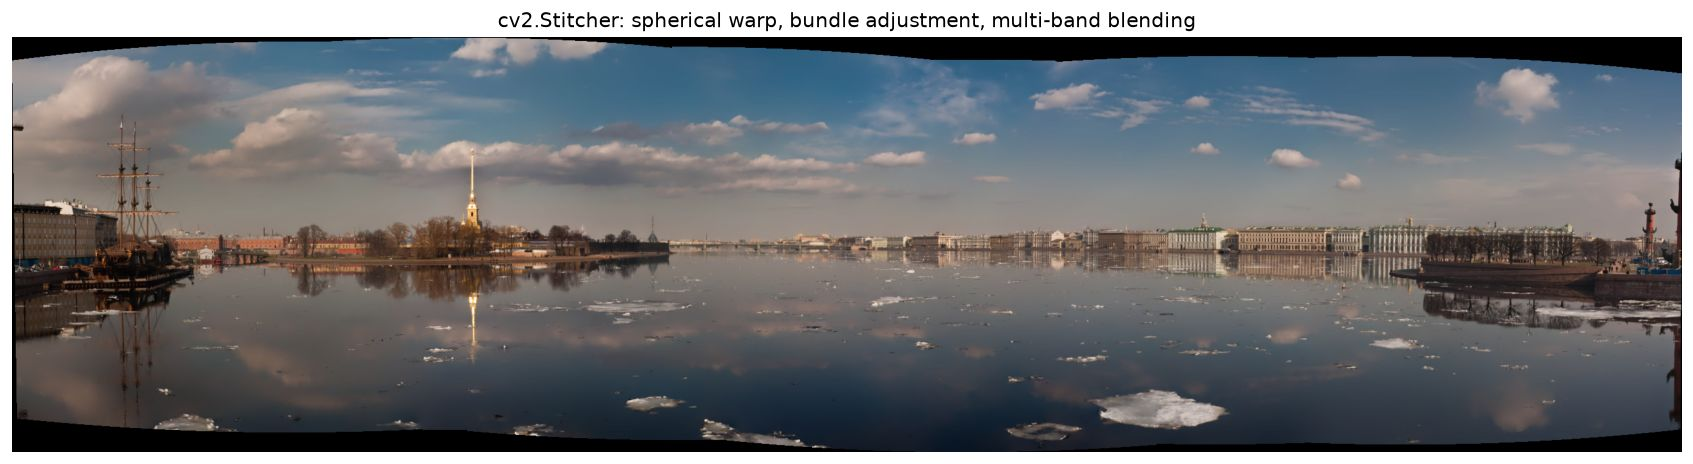

In [16]:
# --- Stitch all six boat frames with cv2.Stitcher (PANORAMA mode) ---
stitcher = cv2.Stitcher_create(cv2.Stitcher_PANORAMA)
with Timer() as t:
    status, pano = stitcher.stitch([cv2.cvtColor(b, cv2.COLOR_RGB2BGR) for b in boats])
assert status == cv2.Stitcher_OK, f"stitching failed with status {status}"
pano = cv2.cvtColor(pano, cv2.COLOR_BGR2RGB)
cams = stitcher.cameras()
focals = np.array([c.focal for c in cams]) / stitcher.workScale()  # focal at input resolution [px]
rel_rot = [geometry.rotation_error_deg(cams[i].R, cams[i + 1].R) for i in range(len(cams) - 1)]
fov_deg = float(np.rad2deg(pano.shape[1] / np.median(focals)))
results["stitcher"] = {"status": int(status), "images_used": len(stitcher.component()), "time_s": t.ms / 1000,
                       "pano_hw": list(pano.shape[:2]), "median_focal_px": float(np.median(focals)),
                       "rotation_between_shots_deg": [float(r) for r in rel_rot],
                       "approx_horizontal_fov_deg": fov_deg}
print(f"status OK, {len(stitcher.component())}/6 images used, {t.ms / 1000:.2f} s, panorama {pano.shape[1]}x{pano.shape[0]} px")
hfov = float(np.rad2deg(2 * np.arctan(960 / 2 / np.median(focals))))
results["stitcher"]["single_image_hfov_deg"] = hfov
print(f"median focal {np.median(focals):.0f} px -> single-image HFOV {hfov:.1f} deg; rotation between shots "
      f"{np.round(rel_rot, 1)} deg")
print(f"consistency: sum of rotations {sum(rel_rot):.1f} deg + one HFOV {hfov:.1f} deg = {sum(rel_rot) + hfov:.1f} deg "
      f"vs panorama span {fov_deg:.1f} deg")
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.imshow(pano)
ax.axis("off")
ax.set_title("cv2.Stitcher: spherical warp, bundle adjustment, multi-band blending")
show_jpeg(fig)

## Results

All measurements were made on the CPU of the test machine (Intel Core Ultra 9 275HX, OpenCV 5.0.0 with its default thread
pool); runtimes are wall-clock means and vary by a few tens of percent between runs.

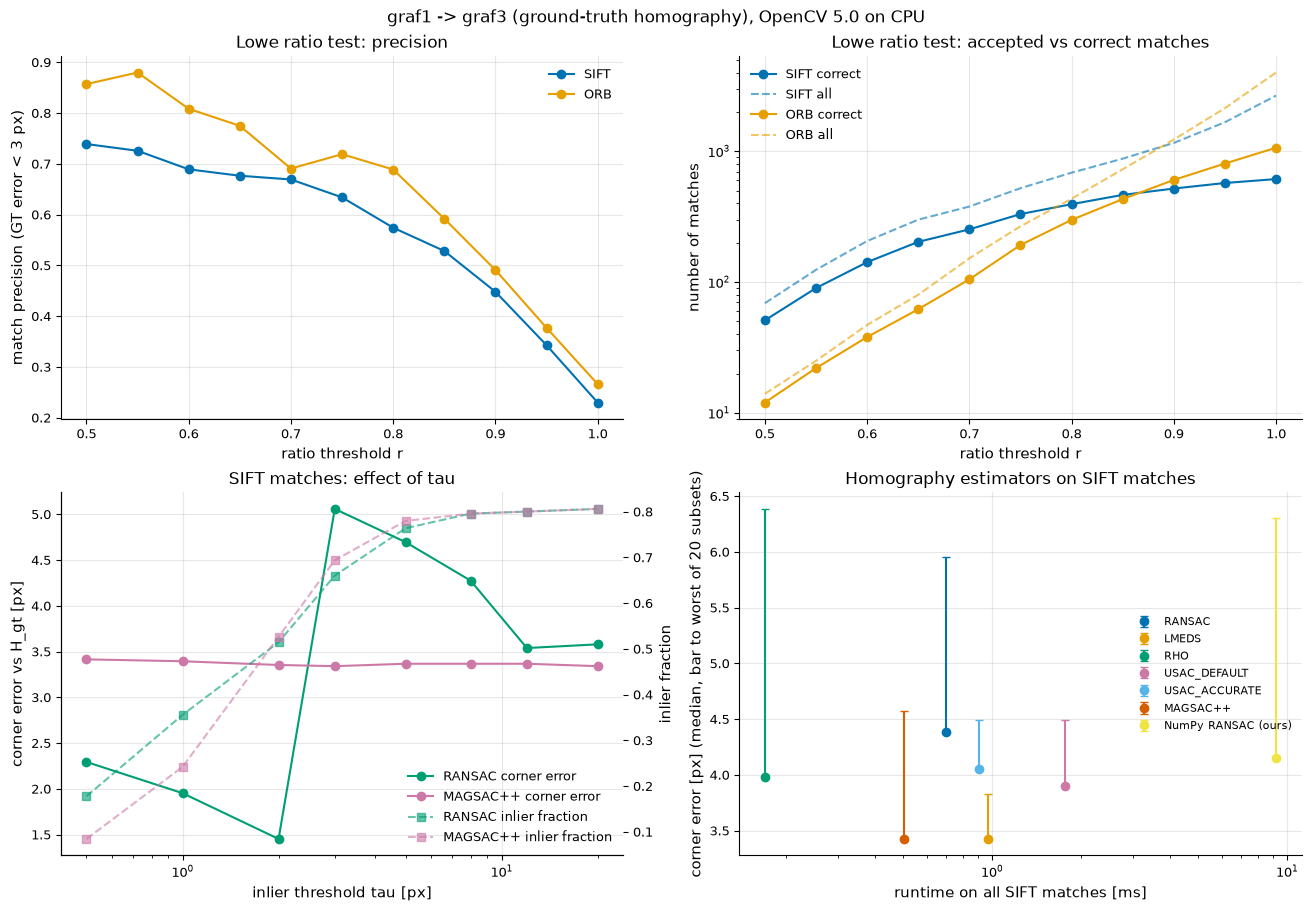

In [17]:
# --- Summary figure: ratio test, inlier threshold and estimator accuracy/speed ---
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for i, name in enumerate(["SIFT", "ORB"]):
    sub = df_ratio[df_ratio.detector == name]
    axes[0, 0].plot(sub["ratio"], sub["precision"], "o-", color=viz.color(i, True), label=name)
    axes[0, 1].plot(sub["ratio"], sub["correct"], "o-", color=viz.color(i, True), label=f"{name} correct")
    axes[0, 1].plot(sub["ratio"], sub["matches"], "--", color=viz.color(i, True), alpha=0.6, label=f"{name} all")
axes[0, 0].set_xlabel("ratio threshold r")
axes[0, 0].set_ylabel("match precision (GT error < 3 px)")
axes[0, 0].set_title("Lowe ratio test: precision")
axes[0, 0].legend()
axes[0, 1].set_yscale("log")
axes[0, 1].set_xlabel("ratio threshold r")
axes[0, 1].set_ylabel("number of matches")
axes[0, 1].set_title("Lowe ratio test: accepted vs correct matches")
axes[0, 1].legend()

for i, mname in enumerate(["RANSAC", "MAGSAC++"]):
    sub = df_tau[df_tau.method == mname]
    axes[1, 0].plot(sub["tau_px"], sub["corner_error_px"], "o-", color=viz.color(i + 2, True), label=f"{mname} corner error")
ax2 = axes[1, 0].twinx()
for i, mname in enumerate(["RANSAC", "MAGSAC++"]):
    sub = df_tau[df_tau.method == mname]
    ax2.plot(sub["tau_px"], sub["inlier_fraction"], "s--", color=viz.color(i + 2, True), alpha=0.6,
             label=f"{mname} inlier fraction")
ax2.set_ylabel("inlier fraction")
ax2.grid(False)
axes[1, 0].set_xscale("log")
axes[1, 0].set_xlabel("inlier threshold tau [px]")
axes[1, 0].set_ylabel("corner error vs H_gt [px]")
axes[1, 0].set_title("SIFT matches: effect of tau")
h_a, l_a = axes[1, 0].get_legend_handles_labels()
h_b, l_b = ax2.get_legend_handles_labels()
axes[1, 0].legend(h_a + h_b, l_a + l_b, loc="lower right")

sub = df_est[df_est.matches == "SIFT"].reset_index(drop=True)
for i, r in sub.iterrows():
    axes[1, 1].errorbar(r["time_ms"], r["corner_err_median_px"],
                        yerr=[[0], [r["corner_err_worst_px"] - r["corner_err_median_px"]]],
                        fmt="o", color=viz.color(i, True), capsize=3, label=r["estimator"])
axes[1, 1].set_xscale("log")
axes[1, 1].set_xlabel("runtime on all SIFT matches [ms]")
axes[1, 1].set_ylabel("corner error [px] (median, bar to worst of 20 subsets)")
axes[1, 1].set_title("Homography estimators on SIFT matches")
axes[1, 1].legend(fontsize=8)
fig.suptitle("graf1 -> graf3 (ground-truth homography), OpenCV 5.0 on CPU")
viz.savefig(fig, PROJECT, "features_ransac_summary")
plt.show()

The tables summarise the detectors/matchers and the estimators (accuracy and speed on both match sets); everything is also
saved to `projects/01_classical_cv/results/nb02_features_homography.json`.

In [18]:
# --- Summary tables + JSON export ---
r08 = df_ratio[df_ratio.ratio == 0.8].set_index("detector")
df_feat_summary = df_det[["detector", "keypoints_graf1", "bytes_per_descriptor", "detect+describe_ms (640x800)",
                          "repeatability@3px", "chance_level@3px"]].set_index("detector")
df_feat_summary["ratio-test matches (r=0.8)"] = r08["matches"]
df_feat_summary["correct (r=0.8)"] = r08["correct"]
df_feat_summary["precision (r=0.8)"] = r08["precision"]
results["feature_summary"] = df_feat_summary.reset_index().to_dict("records")
results["notebook_runtime_s"] = time.perf_counter() - T_START  # setup -> summary, CPU only
print(f"notebook runtime (setup to summary): {results['notebook_runtime_s']:.1f} s")
out = io.save_json(results, RESULTS_DIR / "nb02_features_homography.json")
print("saved", out.relative_to(ROOT))
display(df_feat_summary.round(3))
df_est.round(2)

notebook runtime (setup to summary): 5.3 s
saved projects/01_classical_cv/results/nb02_features_homography.json


,keypoints_graf1,bytes_per_descriptor,detect+describe_ms (640x800),repeatability@3px,chance_level@3px,ratio-test matches (r=0.8),correct (r=0.8),precision (r=0.8)
detector,,,,,,,,
SIFT,2665,512,21.350,0.486,0.148,686,394,0.574
ORB,4000,32,7.135,0.780,0.126,434,299,0.689


,matches,estimator,n_matches,inliers (tau=3),corner_err_median_px,corner_err_worst_px,time_ms
0,SIFT,RANSAC,686,453,4.38,5.95,0.70
1,SIFT,LMEDS,686,418,3.43,3.83,0.97
2,SIFT,RHO,686,417,3.98,6.39,0.17
3,SIFT,USAC_DEFAULT,686,472,3.91,4.50,1.77
4,SIFT,USAC_ACCURATE,686,473,4.06,4.50,0.91
5,SIFT,MAGSAC++,686,476,3.43,4.57,0.50
6,SIFT,NumPy RANSAC (ours),686,396,4.15,6.31,9.19
7,ORB,RANSAC,434,299,1.96,8.63,0.58
8,ORB,LMEDS,434,315,2.52,2.84,1.33
9,ORB,RHO,434,285,1.67,4.10,0.12


### Takeaways

- **Measure on your data; folklore is not enough.** On this strong viewpoint change ORB was not only faster than SIFT, its
  keypoints were also more repeatable (well above the chance level) and its ratio-test matches more precise at every threshold.
  SIFT still delivers more *correct* matches at strict thresholds. ORB's 32-byte binary descriptors (vs 512 bytes for SIFT's
  128 floats) and Hamming matching are why ORB-based systems such as ORB-SLAM run in real time on a CPU.
- **Many "wrong" SIFT matches are near misses.** Small-scale SIFT keypoints are hit hardest by the ~40 degree perspective change:
  they are correct within 3 px less than half the time, while larger keypoints are correct within 10 px almost always.
- **The ratio test is a precision/recall knob.** Tightening $r$ raises precision but discards correct matches; 0.7-0.8 is a good
  default. Cross-checking is cheap but much less selective here.
- **More inliers is not the same as a better model.** At $\tau = 3$ px, `cv2.RANSAC` accepts more inliers than our NumPy RANSAC
  but lands much further from the ground truth at the image corners, because near-miss matches fall inside the threshold and bias
  the final refinement; fitting only the ground-truth-correct matches gives the best possible result (sub-pixel). A smaller $\tau$
  helped plain RANSAC here, while MAGSAC++ was almost insensitive to $\tau$ (but not the most accurate).
- **All OpenCV estimators run in about a millisecond.** Accuracy differences between them depend on the match set; for
  robustness, look at the worst case over perturbed inputs (RANSAC on ORB matches had the largest worst case), not one run.
- **Homographies are exact only for planes and pure rotations.** The planar canvas grows from 1.9 to 71.8 megapixels as frames are
  added, which is why `cv2.Stitcher` estimates focal lengths and rotations, warps to a sphere and blends with multiple bands. Its
  estimates are self-consistent: the summed rotations between consecutive shots plus one image's field of view agree with the
  angular span of the panorama to within a few degrees. (The Stitcher's estimates vary slightly from run to run, by about
  1-2% in focal length on this machine.)

## Exercises

Solutions: `projects/01_classical_cv/solutions/nb02_solutions.py` (run it from the repository root).

**Exercise 1: approximate nearest neighbours.** Replace the brute-force matcher for SIFT with a FLANN k-d tree matcher
(`cv2.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))`). Compare matching time, the number of ratio-test
matches and their precision against the brute-force results. How do `checks` and `trees` trade accuracy for speed?

In [19]:
# --- Exercise 1: FLANN vs brute-force matching for SIFT ---
# TODO: build a FlannBasedMatcher, run knnMatch(d1, d3, k=2) on the SIFT descriptors (float32),
#       apply the ratio test (r = 0.8) and compare time / matches / GT precision with the BFMatcher results above.

**Exercise 2: affine vs projective model.** Fit a 6-DoF affine transform with `cv2.estimateAffine2D(x1s, x3s,
method=cv2.RANSAC, ransacReprojThreshold=3.0)` and compute its corner error against $H_{gt}$ (append `[0, 0, 1]` to the
2x3 matrix). Why does the affine model fail on this pair but work well for small viewpoint changes or distant scenes?

In [20]:
# --- Exercise 2: affine model on the graf matches ---
# TODO: estimate A (2x3) with cv2.estimateAffine2D, convert it to a 3x3 matrix, and compare
#       corner_error(A3) with corner_error(H_cv). Then repeat on matches restricted to the image centre.

**Exercise 3: check the RANSAC iteration formula empirically.** Take the ground-truth-correct SIFT matches, replace a
fraction $\epsilon$ of them with random points (outliers), and run `ransac_homography` with a *fixed* number of iterations
$N$ (disable the adaptive update). Measure over 100 trials how often at least one all-inlier sample was drawn (or simply how
often the corner error is < 5 px) and compare with $1 - (1 - w^4)^N$.

In [21]:
# --- Exercise 3: RANSAC success rate vs theory ---
# TODO: write a fixed-iteration variant of ransac_homography, contaminate the correct matches with
#       outlier ratios 0.3 / 0.5 / 0.7, and plot measured vs predicted success probability against N.